In [1]:
from __future__ import annotations
from typing import Literal

import sys,os
sys.path.insert(0, os.path.abspath(".."))

import time
import diffrax
import equinox as eqx  # https://github.com/patrick-kidger/equinox
import jax
import jax.nn as jnn
import jax.numpy as jnp
import jax.random as jr
import matplotlib.pyplot as plt
import numpy as np
import optax  # https://github.com/deepmind/optax
import pandas as pd

from ude.training import dataloader, train_model
from ude.solver import OdeProblem
from ude.models import NDE, Coculture_Final_Model, Coculture_no_Met1, NSM, UDE
from ude.visualization import display_ODE_coculture
from ude.data import *

### Simulating ground truth data

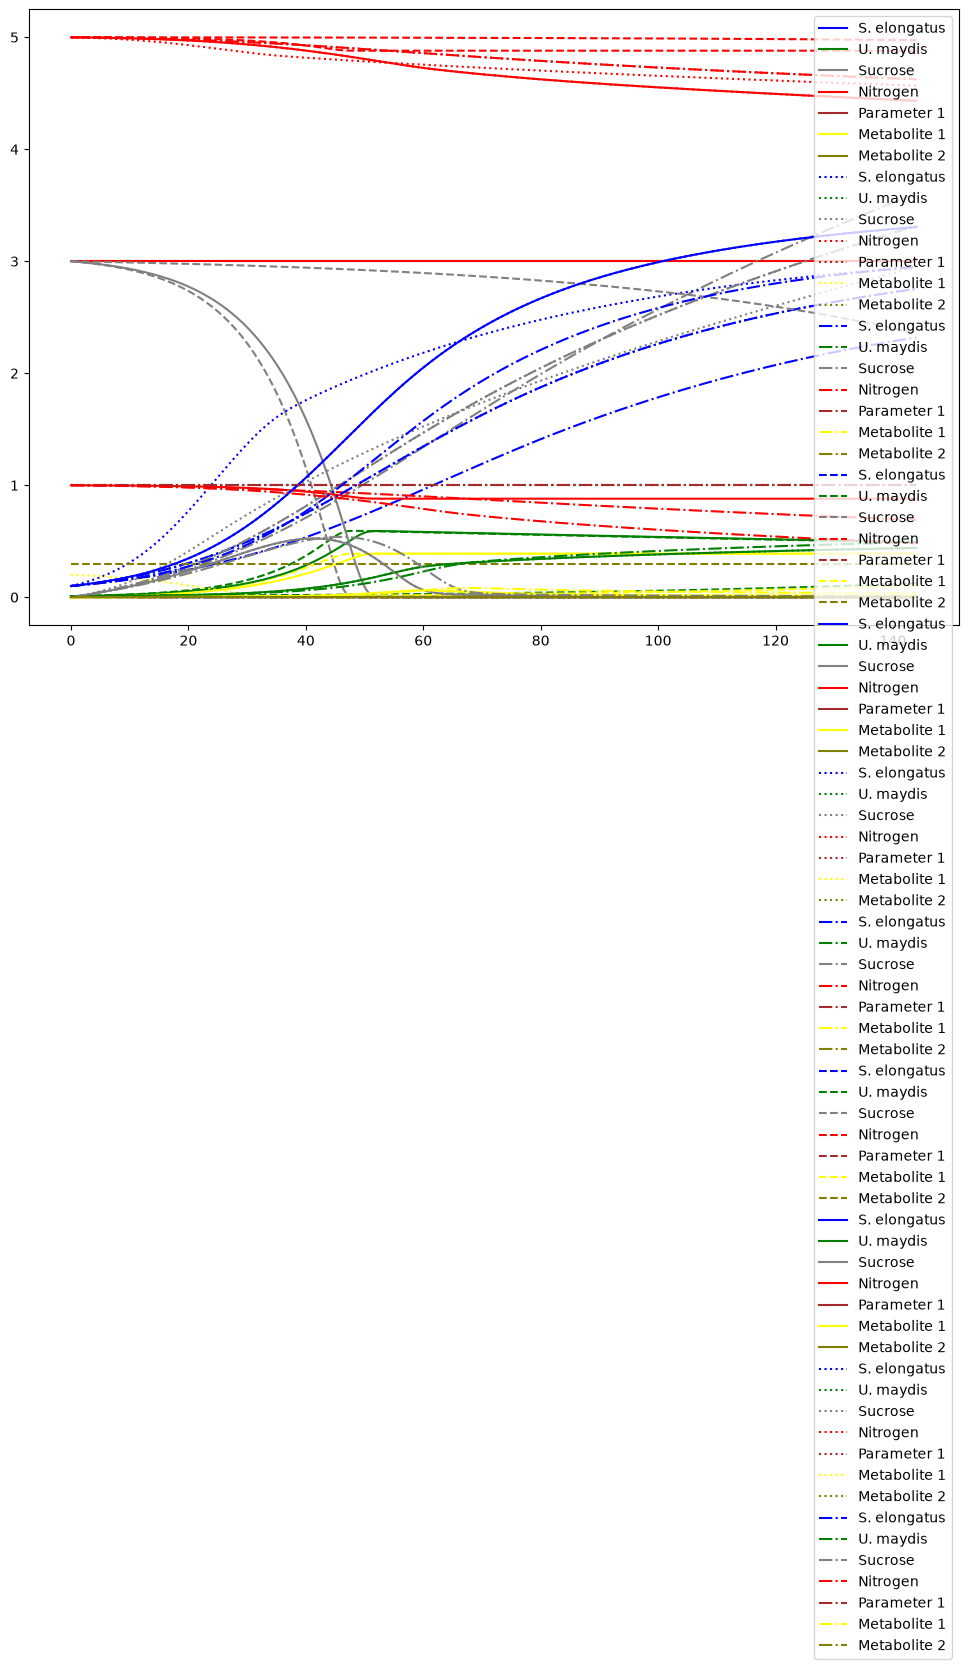

In [2]:
all=["Se","Um","Suc","N","P1","Met1","Met2"]
key = jr.PRNGKey(7)
key_nde, key_param, key_1 = jr.split(key, 3)


coculture_ODE = Coculture_Final_Model(PARAMETERSET_COMMUNITY_Se, PARAMETERSET_COMMUNITY_Um, PARAMETERSET_COMMUNITY_abiotic)
ODE_Problem_Coculture = OdeProblem(
    coculture_ODE,
    full_state=True,
    rtol= 1e-3,
    atol=1e-6,
    max_steps=6000
)

# this is the model of the coculture but there is no information about Met1

ode_core = Coculture_no_Met1(
    parameters_Se = jnp.array(PARAMETERSET_COMMUNITY_Se),
    parameters_Um = jnp.array(PARAMETERSET_COMMUNITY_Um),
    parameters_abiotic = jnp.array(PARAMETERSET_COMMUNITY_abiotic),
)

ODE_Problem_no_met1 = OdeProblem(
    ode_core,
    full_state=True,
    rtol= 1e-3,
    atol=1e-6,
    max_steps=6000
)
t_steps = jnp.linspace(0, 144, 300)

fig, axs = plt.subplots(1, 1, figsize=(12,8))
linesstyles = ["-", ":", "-.", "--",]
i=0

for name, start_condition in start_conditions_df.iterrows():
    linestyle = i%4
    ys,ok = ODE_Problem_Coculture(t_steps,jnp.array(start_condition))
    display_ODE_coculture(t_steps, ys,
        all, axs, line=linesstyles[linestyle])
    i += 1 
plt.legend()

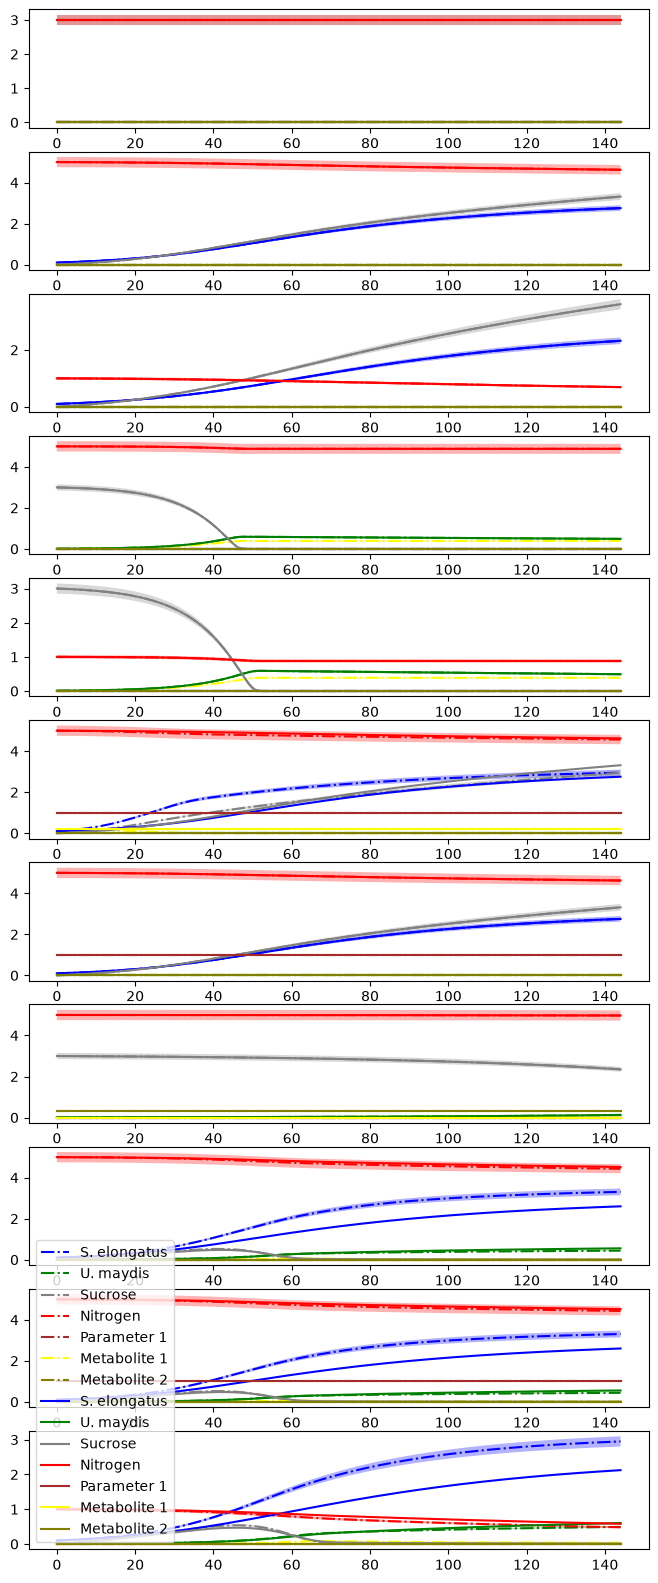

In [3]:
t_steps = jnp.linspace(0, 144, 300)

fig, axs = plt.subplots(11, 1, figsize=(8,20))
i=0

for name,start_condition in start_conditions_df.iterrows():
    ys, ok =ODE_Problem_Coculture(t_steps,jnp.array(start_condition))
    display_ODE_coculture(t_steps, ys,
        all, axs[i], line="-.",std = 0.05 )
    ys_nsm, ok =ODE_Problem_no_met1(t_steps,jnp.array(start_condition))
    display_ODE_coculture(t_steps, ys_nsm,
            all, axs[i], line="-")
    i += 1 
plt.legend()

In [4]:
six=get_timepoint_indices([0,24,48,72,96,144])
ten=get_timepoint_indices([0,8,24,32,48,56,72,80,96,144])
twentyfour=get_timepoint_indices(jnp.linspace(0,144,24))

t_steps = jnp.linspace(0, 144, 300)

list_ys=[]
list_y0=[]
for name,start_condition in start_conditions_df.iterrows():
    ys, ok =ODE_Problem_Coculture(t_steps,jnp.array(start_condition))
    ys_noise = add_noise(ys [twentyfour,:], 0.05 ,key_1)
    list_ys.append(ys_noise)
    list_y0.append(ys_noise[0])
    
data_train= jnp.array(list_ys)
ts_train= t_steps[twentyfour]
y0_full = jnp.array(list_y0)

max_values = jnp.max(data_train, axis=(0,1))
scale = jnp.where(max_values == 0, 1.0, max_values)

scale
print("scale:", scale)
print("type:", type(scale))

scale: [3.0508459  0.62637997 3.3189933  5.6916413  1.0774641  0.40984833
 0.32569999]
type: <class 'jaxlib._jax.ArrayImpl'>


In [5]:
data_train.shape

(11, 24, 7)

In [6]:
nde = NDE(7,7,16,2, key = key_nde)
param= jr.normal(key_param, (20,)) # initialization as in NSM Paper with gaussian around zero
nsm = NSM(nde, param)
nsm_problem = OdeProblem(
    nsm,
    full_state=True,
    rtol= 1e-4,
    atol=1e-6,
    max_steps=300000
)

In [7]:
# nsm_trained = train_model(
#     nsm_problem,
#     data=data_train,          # shape (11, T_train, 2)
#     y0=y0_full,               # shape (11, 7)
#     ts_train=ts_train,
#     steps_strategy=(406,),
#     length_strategy=(1.0,),
#     learning_rate=1e-4,
#     print_every=1,
#     grad_clip = 1.0,
#     scale=scale,
# )

In [8]:
# t_steps = jnp.linspace(0, 144, 300)

# fig, axs = plt.subplots(11, 1, figsize=(8,20))
# i=0

# for name,start_condition in start_conditions_df.iterrows():
#     ys, ok =ODE_Problem_Coculture(t_steps,jnp.array(start_condition))
#     display_ODE_coculture(t_steps, ys,
#         all, axs[i], line="-.")
#     ys_nsm, ok =nsm_trained(t_steps,jnp.array(start_condition))
#     display_ODE_coculture(t_steps, ys_nsm,
#             all, axs[i], line=":")
#     i += 1 
# plt.legend()

In [9]:
nde = NDE(7,7,16,2, key = key_1)

In [10]:
ude = UDE(ode=ode_core, nde=nde, operator="add", lambda_= 0.1, constraint="tanh")

ude_problem = OdeProblem(
    ude, 
    full_state=True,
    rtol= 1e-3,
    atol=1e-6,
    max_steps=300000
)

In [11]:
# first freezing all known parameters (since Equinox Runtime Error occured)
import jax.tree_util as jtu
filter_spec = jtu.tree_map(lambda _: False, ude_problem)
filter_spec = eqx.tree_at(
        lambda tree: tree.rhs.nde,
        filter_spec,
        replace=jtu.tree_map(lambda _: True, ude_problem.rhs.nde),
    )

In [12]:
# Initailize final layer of NDE to be 0
# (since Equinox Runtime Error occured before first training Step)
# -> random initialization is not the cause for the first Equinox Runtime Error
final_layer = ude_problem.rhs.nde.mlp.layers[-1]
new_weights = jnp.zeros_like(final_layer.weight)
new_bias = jnp.zeros_like(final_layer.bias)
ude_problem = eqx.tree_at(
    lambda tree: (tree.rhs.nde.mlp.layers[-1].weight, tree.rhs.nde.mlp.layers[-1].bias),
    ude_problem,
    (new_weights, new_bias)
)

In [13]:
trained_ude = train_model(
    ude_problem,
    data=data_train,          # shape (1, T_train, 2)
    y0=y0_full,               # shape (1, 7)
    ts_train=ts_train,
    steps_strategy=(1000,),
    length_strategy=(1.0,),
    learning_rate=1e-6,
    grad_clip = 1.0,
    print_every=1,
    scale=scale,
    filter_spec=filter_spec
)


── Phase 1/1 (1000 steps, t ∈ [0.00, 92.47]) ──
  Step     0 | Loss 0.019019 | Time 22.805s
  Step     1 | Loss 0.019019 | Time 22.667s


EquinoxRuntimeError: Above is the stack outside of JIT. Below is the stack inside of JIT:
  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\majas\AppData\Roaming\Python\Python312\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "C:\Users\majas\AppData\Roaming\Python\Python312\site-packages\traitlets\config\application.py", line 1075, in launch_instance
    app.start()
  File "C:\Users\majas\AppData\Roaming\Python\Python312\site-packages\ipykernel\kernelapp.py", line 758, in start
    self.io_loop.start()
  File "C:\Users\majas\AppData\Roaming\Python\Python312\site-packages\tornado\platform\asyncio.py", line 211, in start
    self.asyncio_loop.run_forever()
  File "c:\Users\majas\anaconda3\envs\CompBioAc\Lib\asyncio\base_events.py", line 645, in run_forever
    self._run_once()
  File "c:\Users\majas\anaconda3\envs\CompBioAc\Lib\asyncio\base_events.py", line 1999, in _r

In [ ]:
t_steps = jnp.linspace(0, 144, 300)

fig, axs = plt.subplots(11, 1, figsize=(8,20))
i=0

for name,start_condition in start_conditions_df.iterrows():
    ys, ok =ODE_Problem_Coculture(t_steps,jnp.array(start_condition))
    display_ODE_coculture(t_steps, ys,
        all, axs[i], line="-.")
    ys_nsm, ok =nsm_trained(t_steps,jnp.array(start_condition))
    display_ODE_coculture(t_steps, ys_nsm,
            all, axs[i], line=":")
    i += 1 
plt.legend()